In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score,
mean_squared_error, mean_absolute_error, r2_score, silhouette_score
)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering

In [79]:
file_path = 'healthcare-dataset-stroke-data.csv'
df = pd.read_csv(file_path)


Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
None

Summary Statistics (Numerical Attributes):

                 id          age  hypertension  heart_disease  \
count   5110.000000

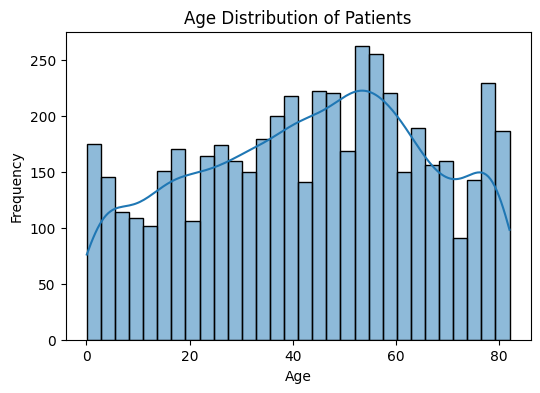

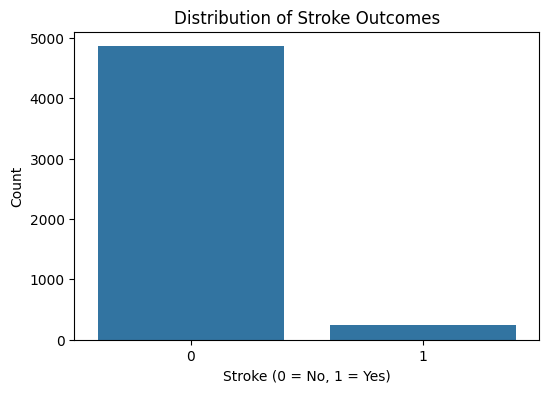

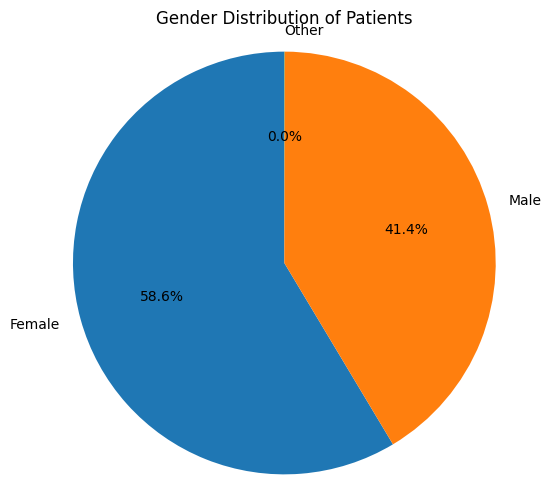

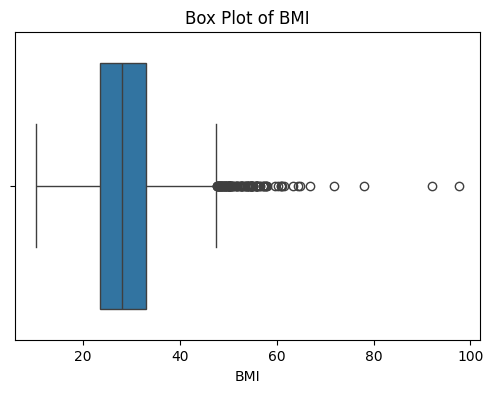

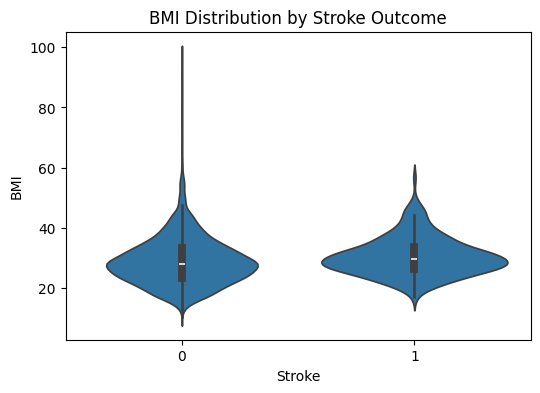

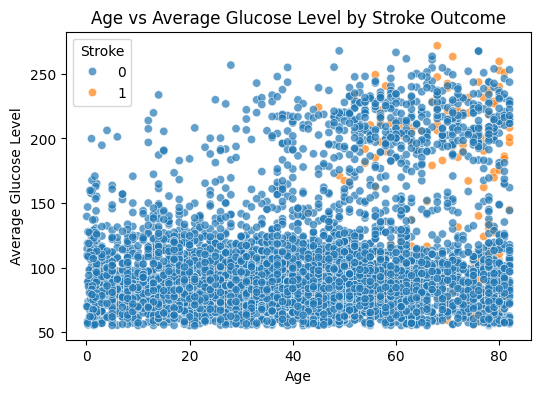

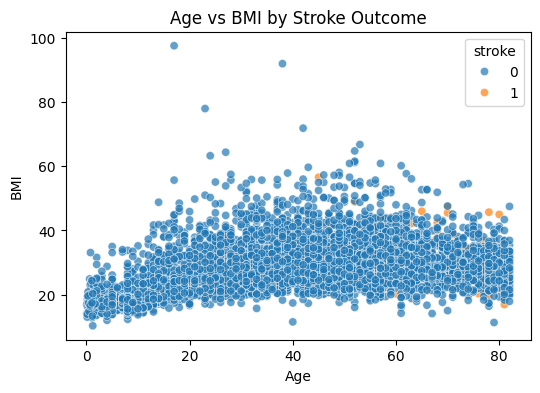

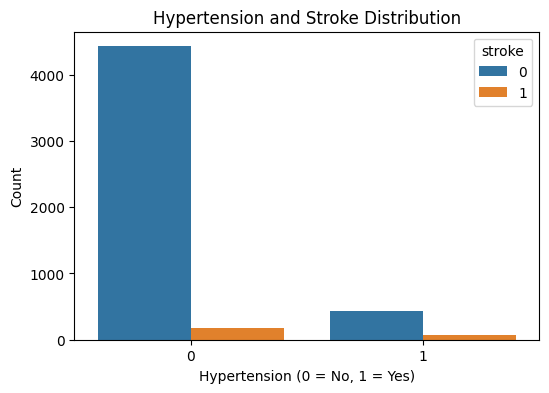

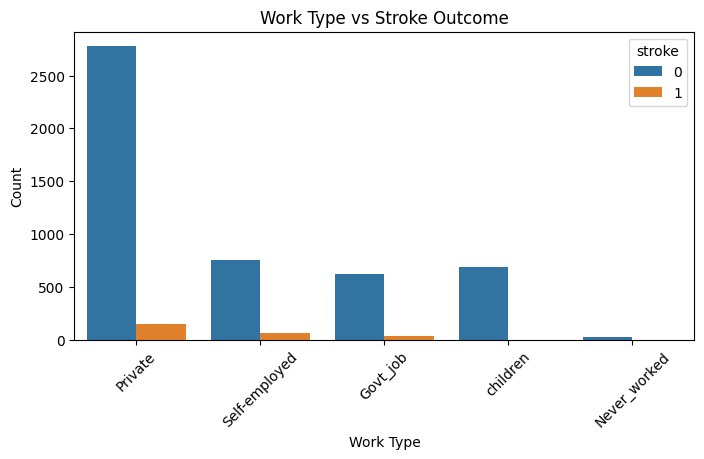

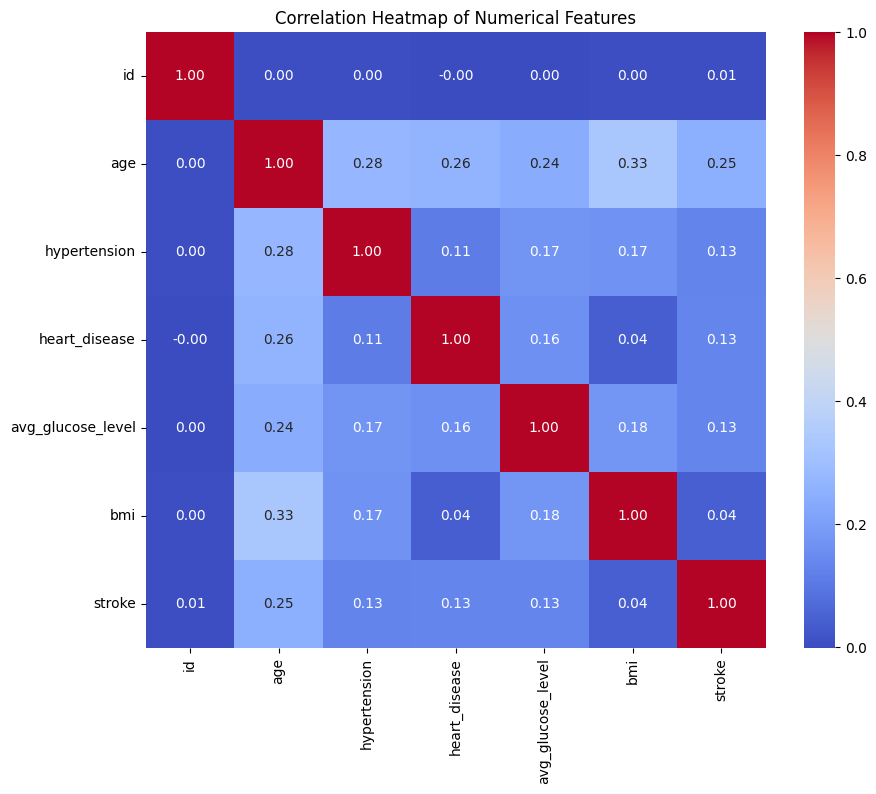

In [82]:
#Task 1( Descriptive analytics):
print("\nDataset Information:\n")
print(df.info())

print("\nSummary Statistics (Numerical Attributes):\n")
print(df.describe())

print("\nSummary Statistics (Categorical Attributes):\n")

#Visualisations

# 1. Histogram: Age Distribution
plt.figure(figsize=(6,4))
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


# 2. Bar chart-stroke outcome distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="stroke")
plt.title("Distribution of Stroke Outcomes")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()


# 3.Pie Chart – Gender Distribution
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Gender Distribution of Patients")
plt.axis("equal")
plt.show()

#4. Box Plot – BMI Distribution
plt.figure(figsize=(6,4))
sns.boxplot(x=df["bmi"])
plt.title("Box Plot of BMI")
plt.xlabel("BMI")
plt.show()

# 5.Violin Plot – BMI by Stroke Outcome
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="stroke", y="bmi")
plt.title("BMI Distribution by Stroke Outcome")
plt.xlabel("Stroke")
plt.ylabel("BMI")
plt.show()


#6. Scatter Plot – Age vs Avg Glucose Level by Stroke
plt.figure(figsize=(6,4))
sns.scatterplot(
    data=df,
    x="age",
    y="avg_glucose_level",
    hue="stroke",
    alpha=0.7
)
plt.title("Age vs Average Glucose Level by Stroke Outcome")
plt.xlabel("Age")
plt.ylabel("Average Glucose Level")
plt.legend(title="Stroke")
plt.show()

#Relationships between multiple variables
# Age × BMI × Stroke
plt.figure(figsize=(6,4))
sns.scatterplot(
    data=df,
    x="age",
    y="bmi",
    hue="stroke",
    alpha=0.7
)
plt.title("Age vs BMI by Stroke Outcome")
plt.xlabel("Age")
plt.ylabel("BMI")
plt.show()

#Hypertension × Stroke × Age

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="hypertension", hue="stroke")
plt.title("Hypertension and Stroke Distribution")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

#Work Type × Stroke × Gender

plt.figure(figsize=(8,4))
sns.countplot(data=df, x="work_type", hue="stroke")
plt.title("Work Type vs Stroke Outcome")
plt.xlabel("Work Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

#Heat Map – Correlation Analysis

plt.figure(figsize=(10,8))
corr = df.select_dtypes(include=["int64", "float64"]).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()




In [83]:
#Task 2:(Data Preparation):

# Method 1: Remove Irrelevant Attribute
if 'id' in df.columns:
    df = df.drop(columns=["id"])

#Method 2: Handle Missing Values
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = df.select_dtypes(include="object").columns.tolist()

num_imputer = SimpleImputer(strategy="median")
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# if there are categorical columns
if cat_cols:
    cat_imputer = SimpleImputer(strategy="most_frequent")
    df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])


# Method 3: Outlier Handling (IQR Capping)
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower, upper)


# Method 4: Discretisation
age_bins = [0, 18, 40, 60, 120]
age_labels = ["Child", "Young Adult", "Middle Aged", "Senior"]

df["age_group"] = pd.cut(df["age"], bins=age_bins, labels=age_labels)

#Method 5: Encoding Categorical Variables
df = pd.get_dummies(df, columns=cat_cols + ["age_group"], drop_first=True)

#Classification-Specific Preparation(stroke prediction)
X_class = df.drop(columns=["stroke"])
y_class = df["stroke"]

#Normalisation (StandardScaler)
scaler_class = StandardScaler()
X_class_scaled = scaler_class.fit_transform(X_class)


#Regression-Specific Preparation(BMI Prediction)
X_reg = df.drop(columns=["bmi"])
y_reg = df["bmi"]

#Feature Scaling
scaler_reg = StandardScaler()
X_reg_scaled = scaler_reg.fit_transform(X_reg)


#Clustering-Specific Preparation
X_cluster = df.drop(columns=["stroke", "bmi"])

#Normalisation (Min-Max Scaling)
scaler_cluster = MinMaxScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

In [84]:
#Task 3(Classification):
# Classification Preparation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder # Added for OneHotEncoder

X = df.drop(columns=["stroke"]) # 'id' column was already dropped in previous cell
y = df["stroke"]

#Preprocessing Pipeline (NO Data Leakage)
# Note: After previous data preparation, most columns are already numerical.
# cat_cols might be empty if all categorical columns were label encoded.
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = X.select_dtypes(include="object").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

#Train–Test Split (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [85]:
# Classification Models
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=7),
    "Support Vector Machine": SVC(kernel="rbf", probability=True)
}

results = []

for name, model in models.items():
    pipeline = ImbPipeline([
        ("preprocessing", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name}")
    print(classification_report(y_test, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.95      0.75      0.82      1022


Random Forest
              precision    recall  f1-score   support

           0       0.96      0.91      0.93       972
           1       0.12      0.26      0.17        50

    accuracy                           0.87      1022
   macro avg       0.54      0.58      0.55      1022
weighted avg       0.92      0.87      0.89      1022


K-Nearest Neighbours
              precision    recall  f1-score   support

           0       0.97      0.82      0.89       972
           1       0.13      0.52      0.21        50

    accuracy                           0.80      1022
   macro avg       0.55      0.67      0.55      1022
weighted avg    

In [86]:
#Result Comparison Table(Classification):
results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.751468,0.140845,0.80,0.239521,0.841070
1,Random Forest,0.873777,0.123810,0.26,0.167742,0.788704
2,K-Nearest Neighbours,0.803327,0.128079,0.52,0.205534,0.764568
3,Support Vector Machine,0.672211,0.111717,0.82,0.196643,0.823230


In [87]:
# Regression Preparation (Predict BMI)
X = df.drop(columns=["bmi"]) # 'id' column was already dropped in previous cell
y = df["bmi"]
#Preprocessing Pipeline (Regression-Safe)
num_cols = ["age", "avg_glucose_level"]
cat_cols = X.select_dtypes(include="object").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

#Train–Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [88]:
# Regression Models
from sklearn.svm import SVR

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ),
    "Support Vector Regressor": SVR(kernel="rbf")
}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("regressor", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)
    })

    print(f"\n{name}")
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("MAE :", mean_absolute_error(y_test, y_pred))
    print("R²  :", r2_score(y_test, y_pred))


Linear Regression
RMSE: 6.550626786985083
MAE : 5.211363756557878
R²  : 0.13734674021459603

Random Forest Regressor
RMSE: 6.595419297829849
MAE : 5.122908506580788
R²  : 0.12550893711262734

Support Vector Regressor
RMSE: 6.03477237856791
MAE : 4.531475729200519
R²  : 0.26786302260480566


In [89]:
# Result Comparison Table(Regression):
results_df = pd.DataFrame(results)
results_df


,Model,RMSE,MAE,R²
0,Linear Regression,6.550627,5.211364,0.137347
1,Random Forest Regressor,6.595419,5.122909,0.125509
2,Support Vector Regressor,6.034772,4.531476,0.267863


In [90]:
# Clustering preparation
X_cluster = pd.get_dummies(X_cluster, drop_first=True) # Redundant, as df already has numerical features
scaler = MinMaxScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

In [91]:
# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

models = {
    "K-Means": KMeans(n_clusters=2, random_state=42),
    "Hierarchical": AgglomerativeClustering(n_clusters=2),
    "Gaussian Mixture Model": GaussianMixture(n_components=2, random_state=42)
}

results = []

for name, model in models.items():

    # GMM uses fit_predict just like the others
    labels = model.fit_predict(X_cluster_scaled)

    # Silhouette score calculation (valid for all three methods)
    if len(set(labels)) > 1:
        score = silhouette_score(X_cluster_scaled, labels)
    else:
        score = np.nan

    results.append({
        "Algorithm": name,
        "Number of Clusters": len(set(labels)),
        "Silhouette Score": score
    })

    print(f"\n{name}")
    print("Clusters:", len(set(labels)))
    print("Silhouette Score:", score)



K-Means
Clusters: 2
Silhouette Score: 0.14918403541800535

Hierarchical
Clusters: 2
Silhouette Score: 0.1567121128228765

Gaussian Mixture Model
Clusters: 2
Silhouette Score: 0.13969504367267313


In [77]:
#Result Comparison Table(cluster):
results_df = pd.DataFrame(results)
results_df



,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,2,0.221118
1,Hierarchical,2,0.230376
2,Gaussian Mixture Model,2,0.221118
